# Spherical synchrotron and Monte Carlo scattering demo

The spatial grid is 1D in radius. Photon packets are sampled in log energy, propagated in 3D vectors, and scattered in batches.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import nonthradsim.Constants as C
from nonthradsim.grid import Grid
from nonthradsim.particle import Particle, Photon
from nonthradsim.distributions import Powerlaw
from nonthradsim.synchrotron import F, synchrotron
from nonthradsim.mc import run_mc
from nonthradsim.observer import plot_bands, spectrum

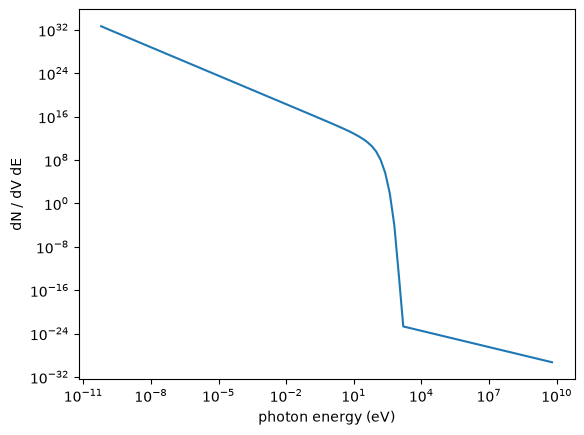

In [2]:
# Build a 1D radial electron profile.
grid = Grid(dimension=1, dx=1e13, n_mesh=101)
particle = Particle(grid, mass=C.me, charge=-1, gm_min=1, gm_max=1e6, n_spectrum=31)
density = 1e10 * np.exp(-(grid.r / grid.radius) ** 2)
Powerlaw(particle, alpha=2.5, gmmin=1, gmmax=1e8, n=density)

photon = Photon(grid, E_min=1e-22, E_max=1e-2, n_spectrum=101)
B = 1e-3 * np.ones(grid.shape)
synchrotron(photon, particle, B, F())

plt.loglog(photon.E * C.erg2eV, photon.value[grid.n_mesh // 2])
plt.xlabel('photon energy (eV)')
plt.ylabel('dN / dV dE')
plt.show()

In [3]:
# Run vectorized batches. Set n_jobs=8 on a machine with enough CPU cores.
escaped = run_mc(
    grid, particle, photon,
    n_particles=200000,
    batch_size=500,
    n_jobs=5,
    seed=123,
)
print(f"escaped packets: {len(escaped['energy'])}")

escaped packets: 200000


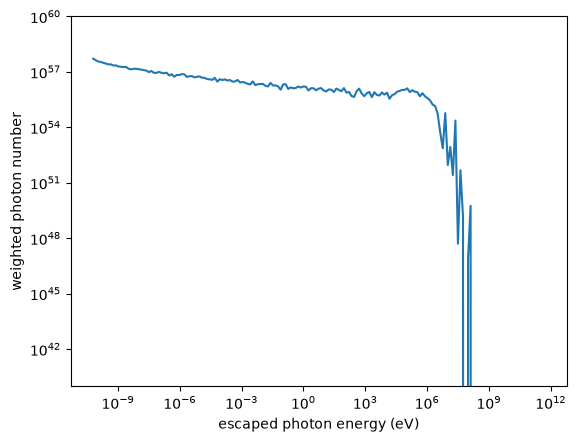

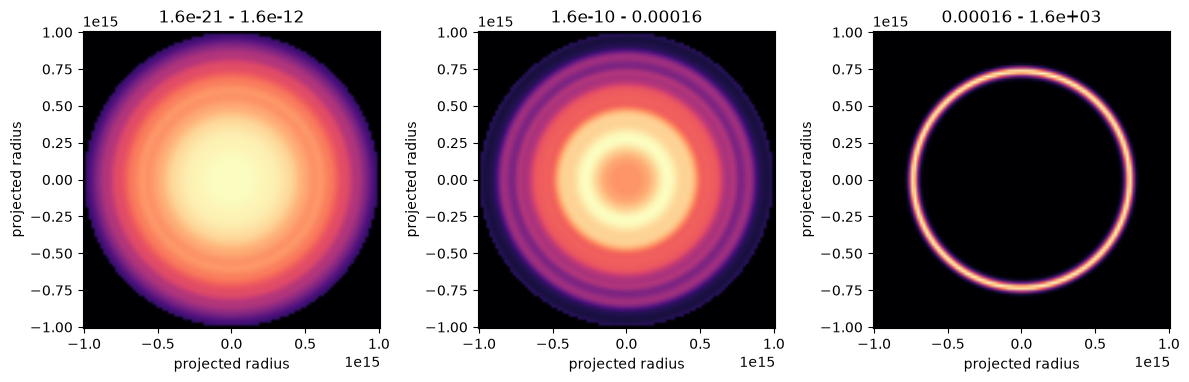

In [4]:
# Accumulate the escaped spectrum and circular sky maps.
from matplotlib import colors as mcolors

energy_edges = np.logspace(-22, 0, 180)
bands = [
    (1e-9 / C.erg2eV, 1e0 / C.erg2eV),
    (1e2 / C.erg2eV, 1e8 / C.erg2eV),
    (1e8 / C.erg2eV, 1e15 / C.erg2eV),
]
escaped_spectrum = spectrum(escaped, energy_edges)
plt.loglog(energy_edges[:-1] * C.erg2eV, escaped_spectrum + 1e-300)
plt.xlabel('escaped photon energy (eV)')
plt.ylabel('weighted photon number')
plt.ylim(1e40,1e60)
# plt.loglog(photon.E * C.erg2eV, photon.value[grid.n_mesh // 2]*1e40)
plt.show()


fig, axes = plot_bands(escaped, grid.radius, energy_edges, bands,image_size=101)#, norm=mcolors.LogNorm())
plt.show()

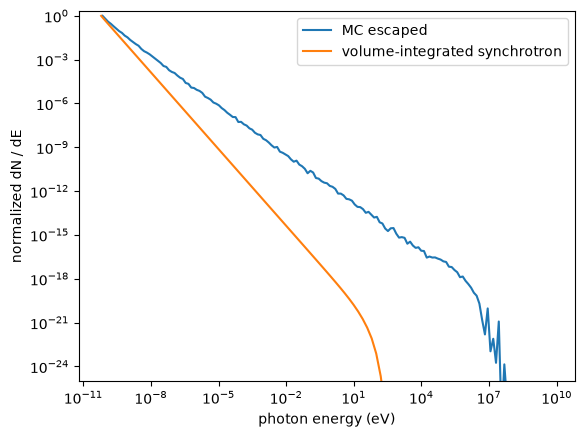

In [5]:
# Compare the volume-integrated synchrotron spectrum with the escaped MC spectrum.
E_center = np.sqrt(energy_edges[:-1] * energy_edges[1:])
dE = np.diff(energy_edges)
escaped_dnde = escaped_spectrum / dE

shell_volume = 4 * np.pi / 3 * (grid.edges[1:]**3 - grid.edges[:-1]**3)
synch_dnde = np.sum(photon.value * shell_volume[:, None], axis=0)

escaped_norm = escaped_dnde / np.max(escaped_dnde)
synch_norm = synch_dnde / np.max(synch_dnde)

mc_mask = escaped_norm > 0
synch_mask = synch_norm > 0
plt.loglog(E_center[mc_mask] * C.erg2eV, escaped_norm[mc_mask], label='MC escaped')
plt.loglog(photon.E[synch_mask] * C.erg2eV, synch_norm[synch_mask], label='volume-integrated synchrotron')
plt.xlabel('photon energy (eV)')
plt.ylabel('normalized dN / dE')
plt.ylim(1e-25, 2)
plt.legend()
plt.show()

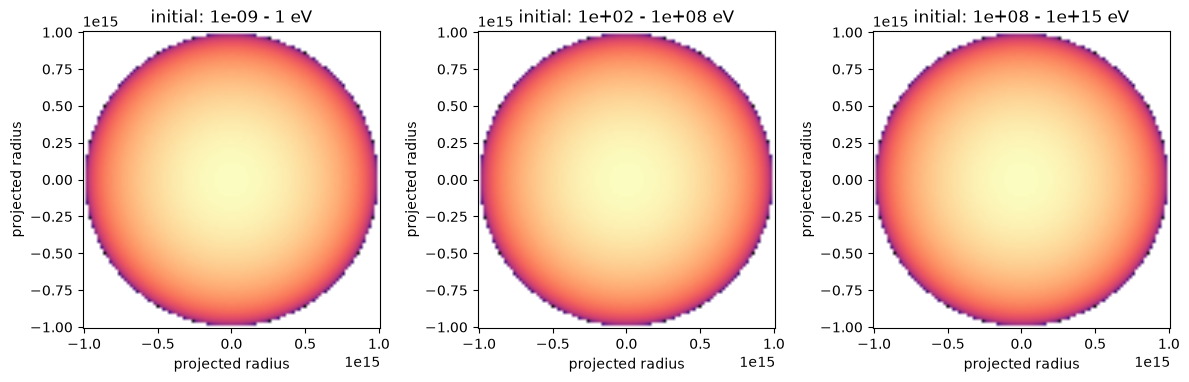

In [6]:
# Project the initial spherical synchrotron field along the line of sight.
# This is a deterministic reference image, before MC transport.
r_centers = 0.5 * (grid.edges[:-1] + grid.edges[1:])
dE_photon = np.gradient(photon.E)
image_size = 101
line_of_sight_points = 1200
axis = np.linspace(-grid.radius, grid.radius, image_size)
xx, yy = np.meshgrid(axis, axis)
impact_parameter = np.sqrt(xx**2 + yy**2)
z_axis = np.linspace(-grid.radius, grid.radius, line_of_sight_points)

fig, axes = plt.subplots(1, len(bands), figsize=(4 * len(bands), 4), squeeze=False)
for i, band in enumerate(bands):
    energy_mask = (photon.E >= band[0]) & (photon.E <= band[1])
    radial_field = np.sum(
        photon.value[:, energy_mask] * dE_photon[energy_mask][None, :],
        axis=1,
    )
    radius_los = np.sqrt(impact_parameter[..., None]**2 + z_axis[None, None, :]**2)
    field_los = np.interp(
        radius_los.ravel(),
        r_centers,
        radial_field,
        left=radial_field[0],
        right=0,
    ).reshape(radius_los.shape)
    field_los[radius_los > grid.radius] = 0
    projected = np.trapezoid(field_los, z_axis, axis=-1)
    projected[impact_parameter > grid.radius] = 0
    positive = projected[projected > 0]
    image_norm = mcolors.LogNorm(vmin=positive.min(), vmax=positive.max()) if positive.size else None
    axes[0, i].imshow(
        projected,
        origin='lower',
        extent=(axis[0], axis[-1], axis[0], axis[-1]),
        cmap='magma',
        norm=image_norm,
        interpolation='bilinear',
    )
    axes[0, i].set_title(f'initial: {band[0] * C.erg2eV:.2g} - {band[1] * C.erg2eV:.2g} eV')
    axes[0, i].set_xlabel('projected radius')
    axes[0, i].set_ylabel('projected radius')
fig.tight_layout()
plt.show()

In [7]:
# Print the fraction of escaped photons that experienced at least one real scattering.
scattered = escaped['n_scatter'] > 0
packet_fraction = np.mean(scattered)
weighted_fraction = np.sum(escaped['weight'][scattered]) / np.sum(escaped['weight'])
print(f' scattered packets: {scattered.sum()} / {scattered.size}')
print(f'packet scattering fraction: {packet_fraction:.6e}')
print(f'weighted scattering fraction: {weighted_fraction:.6e}')

 scattered packets: 133961 / 200000
packet scattering fraction: 6.698050e-01
weighted scattering fraction: 8.168891e-01
